## 1. Imports e configuração

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    fbeta_score, precision_score, recall_score,
    matthews_corrcoef, average_precision_score, confusion_matrix,
    precision_recall_curve
)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


## 2. Carga dos dados e split temporal

In [ ]:
CSV_PATH = "../data/creditcard.csv"

def load_data(csv_path: str) -> pd.DataFrame:
    df = pd.read_csv(csv_path)
    assert {"Time", "Class"} <= set(df.columns), "Colunas Time/Class ausentes"
    n0 = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Duplicatas removidas: {n0 - len(df)}")
    return df

def temporal_split(df: pd.DataFrame, val_frac: float = 0.15, test_frac: float = 0.15):
    """Split temporal em treino/validação/teste, ordenado por 'Time'."""
    df = df.sort_values("Time").reset_index(drop=True)
    n = len(df)
    i_val = int(n * (1 - val_frac - test_frac))
    i_test = int(n * (1 - test_frac))
    train_df = df.iloc[:i_val].copy()
    val_df = df.iloc[i_val:i_test].copy()
    test_df = df.iloc[i_test:].copy()

    for nome, d in [("Treino", train_df), ("Validação", val_df), ("Teste", test_df)]:
        print(f"{nome:<10}: {len(d):>7} transações | Fraudes: {int(d['Class'].sum()):>4} "
              f"({d['Class'].mean()*100:.4f}%)")
    return train_df, val_df, test_df

df = load_data(CSV_PATH)
train_df, val_df, test_df = temporal_split(df)

Duplicatas removidas: 1081
Treino    :  198608 transações | Fraudes:  366 (0.1843%)
Validação :   42559 transações | Fraudes:   55 (0.1292%)
Teste     :   42559 transações | Fraudes:   52 (0.1222%)


## 3. Análise exploratória (EDA)

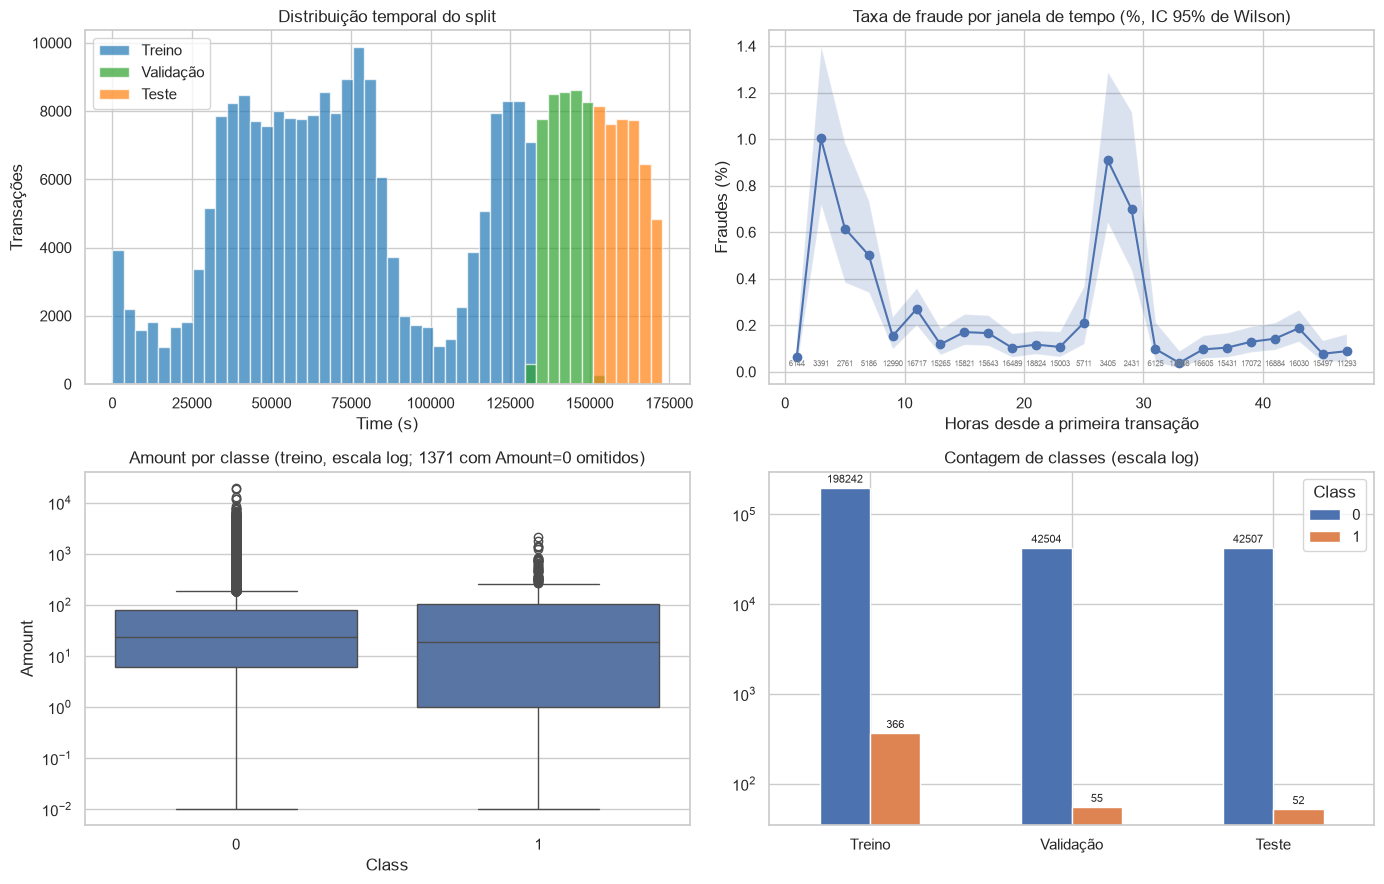

In [ ]:
import os
os.makedirs("../results", exist_ok=True)

def wilson_ci(k, n, z=1.96):
    """Intervalo de confiança de Wilson para proporções."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    margem = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - margem, centro + margem

def plot_eda(train_df, val_df, test_df, n_janelas=24):
    full = pd.concat([train_df, val_df, test_df])
    fig, ax = plt.subplots(2, 2, figsize=(14, 9))

    # 1. Split temporal (bins comuns, para as alturas serem comparáveis)
    bins = np.linspace(full["Time"].min(), full["Time"].max(), 49)
    for d, lbl, c in [(train_df, "Treino", "tab:blue"),
                      (val_df, "Validação", "tab:green"),
                      (test_df, "Teste", "tab:orange")]:
        ax[0, 0].hist(d["Time"], bins=bins, alpha=0.7, label=lbl, color=c)
    ax[0, 0].set_title("Distribuição temporal do split")
    ax[0, 0].set_xlabel("Time (s)")
    ax[0, 0].set_ylabel("Transações")
    ax[0, 0].legend()

    # 2. Taxa de fraude por janela, com IC de Wilson e n por janela
    full = full.assign(janela=pd.cut(full["Time"], bins=n_janelas))
    g = full.groupby("janela", observed=True)["Class"].agg(fraudes="sum", n="count")
    g["taxa"] = g["fraudes"] / g["n"] * 100
    lo, hi = wilson_ci(g["fraudes"], g["n"])
    g["lo"], g["hi"] = lo * 100, hi * 100
    horas = np.array([iv.mid for iv in g.index]) / 3600

    ax[0, 1].plot(horas, g["taxa"], marker="o")
    ax[0, 1].fill_between(horas, g["lo"], g["hi"], alpha=0.2)
    ax[0, 1].set_title("Taxa de fraude por janela de tempo (%, IC 95% de Wilson)")
    ax[0, 1].set_xlabel("Horas desde a primeira transação")
    ax[0, 1].set_ylabel("Fraudes (%)")
    for x, n in zip(horas, g["n"]):
        ax[0, 1].annotate(f"{n}", (x, 0), textcoords="offset points",
                          xytext=(0, 4), ha="center", fontsize=6, color="gray")

    # 3. Amount por classe (apenas Amount > 0, por causa da escala log)
    tr = train_df[train_df["Amount"] > 0]
    sns.boxplot(data=tr, x="Class", y="Amount", ax=ax[1, 0])
    ax[1, 0].set_yscale("log")
    n_zero = int((train_df["Amount"] == 0).sum())
    ax[1, 0].set_title(f"Amount por classe (treino, escala log; {n_zero} com Amount=0 omitidos)")

    # 4. Contagem de classes por conjunto, com rótulos
    contagem = pd.DataFrame({
        "Treino": train_df["Class"].value_counts(),
        "Validação": val_df["Class"].value_counts(),
        "Teste": test_df["Class"].value_counts(),
    }).T
    contagem.plot(kind="bar", ax=ax[1, 1], logy=True)
    for cont in ax[1, 1].containers:
        ax[1, 1].bar_label(cont, fontsize=8, padding=2)
    ax[1, 1].set_title("Contagem de classes (escala log)")
    ax[1, 1].tick_params(axis="x", rotation=0)

    plt.tight_layout()
    plt.savefig("../results/eda.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_eda(train_df, val_df, test_df)

## 4. Avaliação principal (sem Time)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit
from imblearn.pipeline import Pipeline as ImbPipeline

FEATURES = [f"V{i}" for i in range(1, 29)] + ["Amount"]   # sem Time
CONFIGS = [("LR", "peso"), ("LR", "smote"),
           ("NB", "none"), ("NB", "smote"),
           ("RF", "peso"), ("RF", "smote"),
           ("XGB", "peso"), ("XGB", "smote")]

def build_pipe(modelo, balanceamento, features, y_tr):
    """Pipeline sem vazamento: escala (só Amount) -> [SMOTE] -> classificador.
    O SMOTE só atua no fit; na predição o imblearn o ignora."""
    peso = balanceamento == "peso"
    spw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
    if modelo == "LR":
        clf = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                                 class_weight="balanced" if peso else None)
    elif modelo == "NB":
        clf = GaussianNB()
    elif modelo == "RF":
        clf = RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=-1,
                                     random_state=RANDOM_STATE,
                                     class_weight="balanced_subsample" if peso else None)
    elif modelo == "XGB":
        clf = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                            subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                            scale_pos_weight=spw if peso else 1.0, eval_metric="aucpr",
                            n_jobs=-1, random_state=RANDOM_STATE)
    pre = ColumnTransformer([("amt", RobustScaler(), ["Amount"])], remainder="passthrough")
    steps = [("pre", pre)]
    if balanceamento == "smote":
        steps.append(("smote", SMOTE(sampling_strategy=0.1, random_state=RANDOM_STATE)))
    steps.append(("clf", clf))
    return ImbPipeline(steps)

def melhor_limiar_f2(y, s):
    """Limiar que maximiza F2 (usar SOMENTE na validação)."""
    p, r, t = precision_recall_curve(y, s)
    f2 = 5 * p[:-1] * r[:-1] / np.clip(4 * p[:-1] + r[:-1], 1e-12, None)
    return t[np.argmax(f2)]

def metricas(y, s, thr):
    pred = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F2": fbeta_score(y, pred, beta=2, zero_division=0),
            "MCC": matthews_corrcoef(y, pred),
            "PR-AUC": average_precision_score(y, s),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

def bootstrap_ic(y, s, thr, n_boot=500):
    """IC 95% (percentil) de PR-AUC, F2 e MCC no teste, com limiar fixo."""
    rng = np.random.default_rng(RANDOM_STATE)
    y, s = np.asarray(y), np.asarray(s)
    vals = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0:
            continue
        m = metricas(y[i], s[i], thr)
        vals.append((m["PR-AUC"], m["F2"], m["MCC"]))
    lo, hi = np.percentile(np.array(vals), [2.5, 97.5], axis=0)
    return dict(zip(["PR-AUC", "F2", "MCC"], zip(lo, hi)))

def medir_inferencia(pipe, X_te, n_lat=300, n_rep=3):
    """Throughput (lote) e latência (transação unitária, n_jobs=1)."""
    pipe.predict_proba(X_te.iloc[:1000])                      # aquecimento
    tempos = []
    for _ in range(n_rep):
        t0 = time.perf_counter(); pipe.predict_proba(X_te)
        tempos.append(time.perf_counter() - t0)
    vazao = len(X_te) / np.median(tempos)

    pipe.set_params(**{k: 1 for k in pipe.get_params() if k.endswith("n_jobs")})
    amostra = X_te.sample(n_lat, random_state=RANDOM_STATE)
    linhas = [amostra.iloc[[i]] for i in range(n_lat)]        # fora do cronômetro
    for l in linhas[:20]:
        pipe.predict_proba(l)
    lat = []
    for l in linhas:
        t0 = time.perf_counter(); pipe.predict_proba(l)
        lat.append((time.perf_counter() - t0) * 1000)
    return vazao, np.median(lat), np.percentile(lat, 95), np.percentile(lat, 99)

def avaliar(train, val, test, features, configs, rotulo="principal", n_boot=500):
    Xtr, ytr = train[features], train["Class"].values
    Xva, yva = val[features], val["Class"].values
    Xte, yte = test[features], test["Class"].values
    linhas = []
    for modelo, bal in configs:
        nome = f"{modelo}+{bal}"
        pipe = build_pipe(modelo, bal, features, ytr)
        t0 = time.perf_counter(); pipe.fit(Xtr, ytr); t_fit = time.perf_counter() - t0

        s_val = pipe.predict_proba(Xva)[:, 1]
        thr = melhor_limiar_f2(yva, s_val)                    # limiar fixado na validação
        s_te = pipe.predict_proba(Xte)[:, 1]
        m = metricas(yte, s_te, thr)
        ic = bootstrap_ic(yte, s_te, thr, n_boot)
        vazao, l50, l95, l99 = medir_inferencia(pipe, Xte)

        linhas.append({"conjunto": rotulo, "config": nome, "limiar": thr,
                       "PR-AUC (val)": average_precision_score(yva, s_val),
                       **m,
                       "PR-AUC IC": f"[{ic['PR-AUC'][0]:.3f}, {ic['PR-AUC'][1]:.3f}]",
                       "F2 IC": f"[{ic['F2'][0]:.3f}, {ic['F2'][1]:.3f}]",
                       "MCC IC": f"[{ic['MCC'][0]:.3f}, {ic['MCC'][1]:.3f}]",
                       "treino (s)": t_fit, "vazão (tx/s)": vazao,
                       "lat. mediana (ms)": l50, "lat. p95 (ms)": l95, "lat. p99 (ms)": l99})
        print(f"{nome:<10} PR-AUC={m['PR-AUC']:.3f} F2={m['F2']:.3f} MCC={m['MCC']:.3f} "
              f"| treino {t_fit:.1f}s | {vazao:,.0f} tx/s | lat {l50:.2f} ms")
    return pd.DataFrame(linhas)

res_main = avaliar(train_df, val_df, test_df, FEATURES, CONFIGS, "sem Time")
res_main.to_csv("../results/resultados_principal.csv", index=False)
res_main.sort_values("PR-AUC", ascending=False).round(4)

LR+peso    PR-AUC=0.712 F2=0.754 MCC=0.794 | treino 1.8s | 4,254,666 tx/s | lat 2.96 ms
LR+smote   PR-AUC=0.656 F2=0.690 MCC=0.685 | treino 1.6s | 3,870,091 tx/s | lat 2.88 ms
NB+none    PR-AUC=0.056 F2=0.233 MCC=0.201 | treino 0.2s | 1,034,434 tx/s | lat 3.03 ms
NB+smote   PR-AUC=0.055 F2=0.237 MCC=0.203 | treino 0.3s | 1,060,011 tx/s | lat 3.47 ms
RF+peso    PR-AUC=0.775 F2=0.720 MCC=0.681 | treino 20.8s | 442,304 tx/s | lat 10.64 ms
RF+smote   PR-AUC=0.778 F2=0.712 MCC=0.635 | treino 44.7s | 405,242 tx/s | lat 10.36 ms
XGB+peso   PR-AUC=0.761 F2=0.771 MCC=0.806 | treino 6.3s | 611,604 tx/s | lat 3.99 ms
XGB+smote  PR-AUC=0.770 F2=0.760 MCC=0.813 | treino 5.8s | 599,031 tx/s | lat 3.84 ms


,conjunto,config,limiar,PR-AUC (val),Precision,Recall,F2,MCC,PR-AUC,TN,...,FN,TP,PR-AUC IC,F2 IC,MCC IC,treino (s),vazão (tx/s),lat. mediana (ms),lat. p95 (ms),lat. p99 (ms)
5,sem Time,RF+smote,0.1980,0.8740,0.5125,0.7885,0.7118,0.6351,0.7776,42468,...,11,41,"[0.660, 0.876]","[0.608, 0.797]","[0.538, 0.716]",44.7193,4.052420e+05,10.3622,16.3250,20.9944
4,sem Time,RF+peso,0.0899,0.8707,0.6190,0.7500,0.7196,0.6810,0.7751,42483,...,13,39,"[0.663, 0.876]","[0.603, 0.818]","[0.573, 0.767]",20.8230,4.423042e+05,10.6416,14.7402,18.0118
7,sem Time,XGB+smote,0.9017,0.8312,0.9048,0.7308,0.7600,0.8129,0.7696,42503,...,14,38,"[0.648, 0.872]","[0.645, 0.863]","[0.720, 0.890]",5.8289,5.990311e+05,3.8350,5.9762,8.9746
6,sem Time,XGB+peso,0.6566,0.8514,0.8667,0.7500,0.7708,0.8060,0.7614,42501,...,13,39,"[0.641, 0.864]","[0.653, 0.864]","[0.709, 0.880]",6.2628,6.116038e+05,3.9901,5.6810,7.6681
0,sem Time,LR+peso,0.9999,0.8371,0.8636,0.7308,0.7540,0.7942,0.7116,42501,...,14,38,"[0.560, 0.841]","[0.644, 0.858]","[0.684, 0.876]",1.8121,4.254666e+06,2.9626,5.3520,6.3361
1,sem Time,LR+smote,0.9312,0.8077,0.6792,0.6923,0.6897,0.6854,0.6564,42490,...,16,36,"[0.513, 0.796]","[0.579, 0.793]","[0.580, 0.782]",1.5770,3.870091e+06,2.8831,5.6637,8.4764
2,sem Time,NB+none,1.0000,0.0485,0.0669,0.6154,0.2332,0.2005,0.0555,42061,...,20,32,"[0.036, 0.078]","[0.168, 0.293]","[0.152, 0.248]",0.1905,1.034434e+06,3.0260,5.9490,10.2660
3,sem Time,NB+smote,1.0000,0.0510,0.0684,0.6154,0.2367,0.2027,0.0550,42071,...,20,32,"[0.036, 0.077]","[0.170, 0.298]","[0.153, 0.251]",0.2520,1.060011e+06,3.4674,6.1043,8.5351


## 5. Sensibilidade (sin/cos) e validação cruzada temporal

In [5]:
# --- Sensibilidade: ciclo diário (hora do dia) ---
def add_ciclo(d):
    d = d.copy()
    frac = (d["Time"] % 86400) / 86400
    d["hora_sin"] = np.sin(2 * np.pi * frac)
    d["hora_cos"] = np.cos(2 * np.pi * frac)
    return d

FEATURES_CIC = FEATURES + ["hora_sin", "hora_cos"]
tr_c, va_c, te_c = add_ciclo(train_df), add_ciclo(val_df), add_ciclo(test_df)

# configuração escolhida pela PR-AUC de VALIDAÇÃO (nunca pelo teste)
melhor = res_main.sort_values("PR-AUC (val)").iloc[-1]["config"]
mod, bal = melhor.split("+")
print("Config da sensibilidade:", melhor)
res_cic = avaliar(tr_c, va_c, te_c, FEATURES_CIC, [(mod, bal)], "com sin/cos")
res_cic.round(4)

# --- Validação cruzada temporal (janela expansiva) em treino+validação ---
RUN_CV = True
def cv_temporal(trainval, features, configs, n_splits=5):
    X, y = trainval[features], trainval["Class"].values
    out = []
    for modelo, bal in configs:
        aps = []
        for tr, te in TimeSeriesSplit(n_splits=n_splits).split(X):
            pipe = build_pipe(modelo, bal, features, y[tr])
            pipe.fit(X.iloc[tr], y[tr])
            aps.append(average_precision_score(y[te], pipe.predict_proba(X.iloc[te])[:, 1]))
        out.append({"config": f"{modelo}+{bal}", "PR-AUC médio": np.mean(aps),
                    "desvio": np.std(aps), "por fold": np.round(aps, 3).tolist()})
        print(out[-1])
    return pd.DataFrame(out)

if RUN_CV:
    trainval = pd.concat([train_df, val_df])      # já em ordem temporal
    res_cv = cv_temporal(trainval, FEATURES, CONFIGS)
    res_cv.to_csv("../results/resultados_cv_temporal.csv", index=False)
    res_cv.round(4)

Config da sensibilidade: RF+smote
RF+smote   PR-AUC=0.766 F2=0.717 MCC=0.676 | treino 40.1s | 384,035 tx/s | lat 10.68 ms
{'config': 'LR+peso', 'PR-AUC médio': np.float64(0.749885682566837), 'desvio': np.float64(0.07628856883596317), 'por fold': [0.753, 0.625, 0.827, 0.716, 0.829]}
{'config': 'LR+smote', 'PR-AUC médio': np.float64(0.7416690727936095), 'desvio': np.float64(0.06596840229545321), 'por fold': [0.757, 0.663, 0.824, 0.667, 0.798]}
{'config': 'NB+none', 'PR-AUC médio': np.float64(0.07162874993935506), 'desvio': np.float64(0.03446757074225635), 'por fold': [0.094, 0.06, 0.126, 0.029, 0.048]}
{'config': 'NB+smote', 'PR-AUC médio': np.float64(0.07606738314120684), 'desvio': np.float64(0.03525236082795238), 'por fold': [0.105, 0.065, 0.128, 0.032, 0.052]}
{'config': 'RF+peso', 'PR-AUC médio': np.float64(0.7810892193634371), 'desvio': np.float64(0.07061081615765623), 'por fold': [0.832, 0.707, 0.821, 0.686, 0.86]}
{'config': 'RF+smote', 'PR-AUC médio': np.float64(0.791079758572543

## 6. Benchmark de inferência (latência e vazão)

In [6]:
import gc, platform, sys, sklearn, xgboost, imblearn

def info_ambiente():
    return {"SO": platform.platform(), "CPU": platform.processor(),
            "núcleos lógicos": os.cpu_count(), "Python": sys.version.split()[0],
            "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
            "imbalanced-learn": imblearn.__version__}

def _lat(fn, entradas, aquec=30):
    """Latência (ms) de cada chamada, com GC desligado durante a medição."""
    for e in entradas[:aquec]:
        fn(e)
    gc.collect(); gc.disable()
    try:
        out = []
        for e in entradas:
            t0 = time.perf_counter(); fn(e)
            out.append((time.perf_counter() - t0) * 1000)
    finally:
        gc.enable()
    return np.array(out)

def _lat_rep(fn, entradas, n_rep):
    """Mediana das medianas + p95/p99 das latências agrupadas de todas as repetições."""
    todas = [_lat(fn, entradas) for _ in range(n_rep)]
    return (np.median([np.median(l) for l in todas]),
            *np.percentile(np.concatenate(todas), [95, 99]))

def _vazao(fn, X, n_rep=5):
    fn(X[:1000])                                            # aquecimento
    ts = []
    for _ in range(n_rep):
        t0 = time.perf_counter(); fn(X); ts.append(time.perf_counter() - t0)
    return len(X) / np.median(ts)

def bench_inferencia(train, test, features, configs, n_lat=300, n_rep=5):
    Xtr, ytr, Xte = train[features], train["Class"].values, test[features]
    pos = np.random.default_rng(RANDOM_STATE).choice(len(Xte), n_lat, replace=False)
    linhas_df = [Xte.iloc[[i]] for i in pos]               # montadas fora do cronômetro
    rows = []
    for modelo, bal in configs:
        pipe = build_pipe(modelo, bal, features, ytr)
        pipe.fit(Xtr, ytr)
        pre, clf = pipe.named_steps["pre"], pipe.named_steps["clf"]

        v_todos = _vazao(pipe.predict_proba, Xte, n_rep)    # núcleos padrão (RF/XGB: todos)
        pipe.set_params(**{k: 1 for k in pipe.get_params() if k.endswith("n_jobs")})
        v_1 = _vazao(pipe.predict_proba, Xte, n_rep)        # 1 thread (comparação justa)

        Xt = pre.transform(Xte)
        linhas_np = [Xt[i:i + 1] for i in pos]
        comp = _lat_rep(pipe.predict_proba, linhas_df, n_rep)   # pipeline completo
        prep = _lat_rep(pre.transform, linhas_df, n_rep)        # só pré-processamento
        mod = _lat_rep(clf.predict_proba, linhas_np, n_rep)     # só o modelo

        rows.append({"config": f"{modelo}+{bal}",
                     "vazão 1 thread (tx/s)": v_1, "vazão todos núcleos (tx/s)": v_todos,
                     "pipeline: mediana (ms)": comp[0], "pipeline: p95": comp[1], "pipeline: p99": comp[2],
                     "pré-proc.: mediana (ms)": prep[0],
                     "modelo: mediana (ms)": mod[0], "modelo: p95": mod[1], "modelo: p99": mod[2]})
        print(f"{modelo}+{bal:<6} pipeline {comp[0]:.2f} ms | pré-proc. {prep[0]:.2f} ms | "
              f"modelo {mod[0]:.2f} ms | {v_1:,.0f} tx/s (1 thread)")
    return pd.DataFrame(rows)

# O custo de inferência não depende da técnica de balanceamento, então basta um por modelo
CONFIGS_INF = [("LR", "peso"), ("NB", "none"), ("RF", "peso"), ("XGB", "peso")]
amb = info_ambiente()
print(amb)
pd.Series(amb).to_csv("../results/ambiente.csv", header=["valor"])

res_inf = bench_inferencia(train_df, test_df, FEATURES, CONFIGS_INF)
res_inf.to_csv("../results/resultados_inferencia.csv", index=False)
res_inf.round(3)

{'SO': 'Windows-11-10.0.26200-SP0', 'CPU': 'Intel64 Family 6 Model 154 Stepping 4, GenuineIntel', 'núcleos lógicos': 8, 'Python': '3.12.6', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'imbalanced-learn': '0.14.2'}
LR+peso   pipeline 3.52 ms | pré-proc. 4.66 ms | modelo 0.19 ms | 3,082,221 tx/s (1 thread)
NB+none   pipeline 5.59 ms | pré-proc. 4.74 ms | modelo 0.33 ms | 730,603 tx/s (1 thread)
RF+peso   pipeline 16.45 ms | pré-proc. 4.74 ms | modelo 11.07 ms | 106,483 tx/s (1 thread)
XGB+peso   pipeline 7.72 ms | pré-proc. 5.27 ms | modelo 1.27 ms | 136,582 tx/s (1 thread)


,config,vazão 1 thread (tx/s),vazão todos núcleos (tx/s),pipeline: mediana (ms),pipeline: p95,pipeline: p99,pré-proc.: mediana (ms),modelo: mediana (ms),modelo: p95,modelo: p99
0,LR+peso,3082221.044,3279091.451,3.516,7.303,10.510,4.656,0.194,0.282,0.451
1,NB+none,730602.780,735234.923,5.595,7.561,11.828,4.738,0.333,0.630,1.015
2,RF+peso,106483.086,152675.946,16.446,28.435,42.037,4.738,11.069,18.339,28.324
3,XGB+peso,136582.420,126635.838,7.717,11.129,15.540,5.265,1.274,2.183,3.478
